In [68]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error

df=pd.read_csv("water_potability_lab2start.csv")

X_cls=df.drop(columns=["Potability"])
y_cls=df["Potability"]

X_train_cls, X_test_cls, y_train_cls, y_test_cls=train_test_split(X_cls, y_cls, test_size=0.2, random_state=42, stratify=y_cls)

print(f"Обучающая выборка: {X_train_cls.shape}")
print(f"Тестовая выборка: {X_test_cls.shape}")

Обучающая выборка: (2620, 9)
Тестовая выборка: (656, 9)


In [69]:
X_reg=df.drop(columns=["ph"])
y_reg=df["ph"]

X_train_reg, X_test_reg, y_train_reg, y_test_reg=train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

reg_model=LinearRegression()
reg_model.fit(X_train_reg, y_train_reg)

y_pred_reg=reg_model.predict(X_test_reg)

In [70]:
mse=mean_squared_error(y_test_reg, y_pred_reg)
rmse=root_mean_squared_error(y_test_reg, y_pred_reg)
mae=mean_absolute_error(y_test_reg, y_pred_reg)

print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAE:  {mae:.4f}")


MSE:  0.0112
RMSE: 0.1059
MAE:  0.0775


In [77]:
from sklearn.ensemble import RandomForestClassifier

cls_model = RandomForestClassifier(class_weight="balanced", random_state=42)
cls_model.fit(X_train_cls, y_train_cls)

y_pred_cls = cls_model.predict(X_test_cls)

Точность: 0.6524390243902439
              precision    recall  f1-score   support

           0       0.69      0.78      0.73       400
           1       0.57      0.45      0.50       256

    accuracy                           0.65       656
   macro avg       0.63      0.62      0.62       656
weighted avg       0.64      0.65      0.64       656



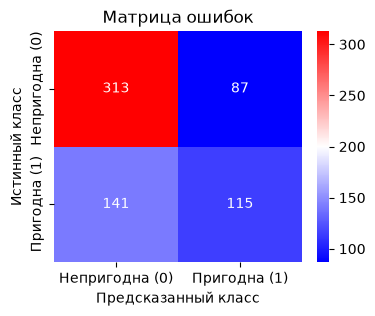

In [78]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

accuracy=accuracy_score(y_test_cls, y_pred_cls)
print("Точность:", accuracy)

report=classification_report(y_test_cls, y_pred_cls)
print(report)

cm = confusion_matrix(y_test_cls, y_pred_cls)

plt.figure(figsize=(4, 3))
sns.heatmap(cm,annot=True,fmt="d",cmap="bwr", xticklabels=["Непригодна (0)", "Пригодна (1)"],yticklabels=["Непригодна (0)", "Пригодна (1)"],)
plt.title("Матрица ошибок")
plt.ylabel("Истинный класс")
plt.xlabel("Предсказанный класс")
plt.show()